<a href="https://colab.research.google.com/github/vivianagonzalez203/Bootcamp-Data-Science/blob/main/03_Datos%20%26%20Visualizaci%C3%B3n/Clase_12_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clase 12 – Análisis exploratorio de datos (EDA)

## Objetivos
- Inspeccionar la estructura de un conjunto de datos.
- Identificar valores faltantes, duplicados, inconsistencias y valores sospechosos.
- Explorar variables individuales y relaciones entre variables.
- Unir tablas con `merge()`, `concat()` y `join()`.
- Documentar hallazgos con evidencia.


## 1. Preparación del entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.0.6
NumPy: 2.5.3


## 2. Crear datos de práctica

Simularemos dos tablas:
- **clientes:** datos demográficos y tipo de suscripción.
- **transacciones:** compras realizadas por los clientes.

Incluiremos problemas intencionales para practicar el diagnóstico: edades imposibles, categorías inconsistentes, fechas en formatos diferentes, valores faltantes y duplicados.


In [2]:
rng = np.random.default_rng(42)

n_clientes = 60
customer_ids = np.arange(1001, 1001 + n_clientes)

clientes = pd.DataFrame({
    "Customer_ID": customer_ids,
    "Age": rng.integers(18, 70, n_clientes),
    "Gender": rng.choice(["Femenino", "Masculino"], n_clientes),
    "City": rng.choice(["Pereira", "Bogota", "Medellin", "Cali"], n_clientes),
    "Subscription": rng.choice(["Basic", "Premium", "Standard"], n_clientes)
})

# Problemas intencionales
clientes.loc[2, "Age"] = 999
clientes.loc[7, "Age"] = np.nan
clientes.loc[4, "City"] = " pereira "
clientes.loc[9, "City"] = "BOGOTA"
clientes.loc[12, "Gender"] = np.nan

n_transacciones = 155
fechas = pd.date_range("2025-01-01", "2025-06-30", periods=n_transacciones)

transacciones = pd.DataFrame({
    "Transaction_ID": np.arange(50001, 50001 + n_transacciones),
    "Customer_ID": rng.choice(customer_ids, n_transacciones),
    "Date": [fecha.strftime("%Y-%m-%d") for fecha in fechas],
    "Amount": np.round(rng.uniform(25000, 450000, n_transacciones), 0),
    "Payment_Method": rng.choice(
        ["Tarjeta", "Efectivo", "Transferencia"], n_transacciones
    )
})

# Fechas con formatos variados y un monto faltante
transacciones.loc[1, "Date"] = "15/02/2025"
transacciones.loc[3, "Date"] = "Mar 08 2025"
transacciones.loc[5, "Amount"] = np.nan

# Categorías inconsistentes y fila duplicada
transacciones.loc[8, "Payment_Method"] = " tarjeta "
transacciones.loc[14, "Payment_Method"] = "TARJETA"
transacciones = pd.concat(
    [transacciones, transacciones.iloc[[10]]],
    ignore_index=True
)

display(clientes.head())
display(transacciones.head())

,Customer_ID,Age,Gender,City,Subscription
0,1001,22.0,Masculino,Bogota,Standard
1,1002,58.0,Masculino,Medellin,Basic
2,1003,999.0,Femenino,Medellin,Premium
3,1004,40.0,Masculino,Bogota,Standard
4,1005,40.0,Femenino,pereira,Premium


,Transaction_ID,Customer_ID,Date,Amount,Payment_Method
0,50001,1009,2025-01-01,108485.0,Transferencia
1,50002,1036,15/02/2025,156888.0,Tarjeta
2,50003,1006,2025-01-03,355397.0,Efectivo
3,50004,1039,Mar 08 2025,438026.0,Efectivo
4,50005,1038,2025-01-05,237815.0,Efectivo


## 3. Inspección inicial

Antes de limpiar, revisamos tamaño, columnas, tipos y primeras observaciones.

In [3]:
print("Dimensiones de transacciones:", transacciones.shape)

display(transacciones.head())
display(transacciones.tail())

transacciones.info()

display(transacciones.describe())
display(transacciones.describe(include="object"))
display(transacciones.dtypes)

Dimensiones de transacciones: (156, 5)


,Transaction_ID,Customer_ID,Date,Amount,Payment_Method
0,50001,1009,2025-01-01,108485.0,Transferencia
1,50002,1036,15/02/2025,156888.0,Tarjeta
2,50003,1006,2025-01-03,355397.0,Efectivo
3,50004,1039,Mar 08 2025,438026.0,Efectivo
4,50005,1038,2025-01-05,237815.0,Efectivo


,Transaction_ID,Customer_ID,Date,Amount,Payment_Method
151,50152,1011,2025-06-26,65396.0,Tarjeta
152,50153,1023,2025-06-27,286870.0,Tarjeta
153,50154,1036,2025-06-28,97799.0,Transferencia
154,50155,1044,2025-06-30,265104.0,Transferencia
155,50011,1011,2025-01-12,76779.0,Transferencia


<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  156 non-null    int64  
 1   Customer_ID     156 non-null    int64  
 2   Date            156 non-null    str    
 3   Amount          155 non-null    float64
 4   Payment_Method  156 non-null    str    
dtypes: float64(1), int64(2), str(2)
memory usage: 6.2 KB


,Transaction_ID,Customer_ID,Amount
count,156.000000,156.000000,155.000000
mean,50077.570513,1029.205128,231544.767742
std,45.064128,17.783544,124440.348211
min,50001.000000,1001.000000,30923.000000
25%,50038.750000,1013.750000,116813.000000
50%,50077.500000,1029.000000,237815.000000
75%,50116.250000,1045.000000,348726.500000
max,50155.000000,1060.000000,441318.000000


C:\Users\maria\AppData\Local\Temp\ipykernel_31040\3784448059.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(transacciones.describe(include="object"))


,Date,Payment_Method
count,156,156
unique,155,5
top,2025-01-12,Transferencia
freq,2,61


Transaction_ID      int64
Customer_ID         int64
Date                  str
Amount            float64
Payment_Method        str
dtype: object

### ¿Qué nos aporta cada método?
- `head()`: muestra los primeros registros.
- `shape`: devuelve filas y columnas.
- `info()`: muestra tipos y cantidad de valores no nulos.
- `describe()`: resume estadísticamente las variables.
- `dtypes`: permite consultar el tipo de cada columna.

**Idea para explicar:** un identificador puede estar almacenado como número, pero no tiene sentido calcular su promedio porque no representa una magnitud.


## 4. Calidad de los datos

### 4.1 Valores faltantes

In [4]:
display(transacciones.isna().sum().to_frame("valores_faltantes"))

porcentaje_faltantes = (
    transacciones.isna().mean().mul(100).round(2)
)
display(porcentaje_faltantes.to_frame("porcentaje_faltante"))

,valores_faltantes
Transaction_ID,0
Customer_ID,0
Date,0
Amount,1
Payment_Method,0


,porcentaje_faltante
Transaction_ID,0.00
Customer_ID,0.00
Date,0.00
Amount,0.64
Payment_Method,0.00


### 4.2 Registros duplicados

In [5]:
print("Duplicados completos:", transacciones.duplicated().sum())

display(
    transacciones[transacciones.duplicated(keep=False)]
    .sort_values("Transaction_ID")
)

print(
    "Transaction_ID duplicados:",
    transacciones["Transaction_ID"].duplicated().sum()
)

Duplicados completos: 1


,Transaction_ID,Customer_ID,Date,Amount,Payment_Method
10,50011,1011,2025-01-12,76779.0,Transferencia
155,50011,1011,2025-01-12,76779.0,Transferencia


Transaction_ID duplicados: 1


### 4.3 Valores sospechosos o imposibles

In [6]:
display(clientes[clientes["Age"] > 100])

# El límite razonable debe definirse según el contexto.
# Un valor extremo no es automáticamente un error.

,Customer_ID,Age,Gender,City,Subscription
2,1003,999.0,Femenino,Medellin,Premium


### 4.4 Categorías inconsistentes

In [8]:
display(clientes["City"].value_counts(dropna=False))
display(transacciones["Payment_Method"].value_counts(dropna=False))

City
Bogota       16
Medellin     16
Pereira      13
Cali         13
 pereira      1
BOGOTA        1
Name: count, dtype: int64

Payment_Method
Transferencia    61
Tarjeta          52
Efectivo         41
 tarjeta          1
TARJETA           1
Name: count, dtype: int64

### 4.5 Limpieza de ejemplo

Para este ejercicio:
- Marcamos edades menores de 0 o mayores de 100 como faltantes.
- Quitamos espacios y estandarizamos el formato de texto.
- Convertimos fechas con `errors="coerce"` para detectar las que no se interpretan.
- Eliminamos duplicados exactos.

En un proyecto real, cada regla debe justificarse y documentarse.


In [9]:
clientes_limpios = clientes.copy()
transacciones_limpias = transacciones.copy()

clientes_limpios.loc[
    (clientes_limpios["Age"] < 0) | (clientes_limpios["Age"] > 100),
    "Age"
] = np.nan

clientes_limpios["City"] = (
    clientes_limpios["City"]
    .astype("string")
    .str.strip()
    .str.title()
)

transacciones_limpias["Payment_Method"] = (
    transacciones_limpias["Payment_Method"]
    .astype("string")
    .str.strip()
    .str.title()
)

transacciones_limpias["Date"] = pd.to_datetime(
    transacciones_limpias["Date"],
    errors="coerce",
    dayfirst=True
)

transacciones_limpias = transacciones_limpias.drop_duplicates()

display(clientes_limpios.head())
display(transacciones_limpias.head())

print("Duplicados restantes:", transacciones_limpias.duplicated().sum())
print("Fechas no interpretadas:", transacciones_limpias["Date"].isna().sum())

,Customer_ID,Age,Gender,City,Subscription
0,1001,22.0,Masculino,Bogota,Standard
1,1002,58.0,Masculino,Medellin,Basic
2,1003,NaN,Femenino,Medellin,Premium
3,1004,40.0,Masculino,Bogota,Standard
4,1005,40.0,Femenino,Pereira,Premium


,Transaction_ID,Customer_ID,Date,Amount,Payment_Method
0,50001,1009,2025-01-01,108485.0,Transferencia
1,50002,1036,NaT,156888.0,Tarjeta
2,50003,1006,2025-03-01,355397.0,Efectivo
3,50004,1039,NaT,438026.0,Efectivo
4,50005,1038,2025-05-01,237815.0,Efectivo


Duplicados restantes: 0
Fechas no interpretadas: 95


## 5. Análisis univariado

Analizamos una variable a la vez. La herramienta depende de si la variable es numérica o categórica.

### 5.1 Variable numérica: edad


count    58.000000
mean     44.551724
std      14.530274
min      20.000000
25%      33.000000
50%      44.500000
75%      57.000000
max      68.000000
Name: Age, dtype: float64

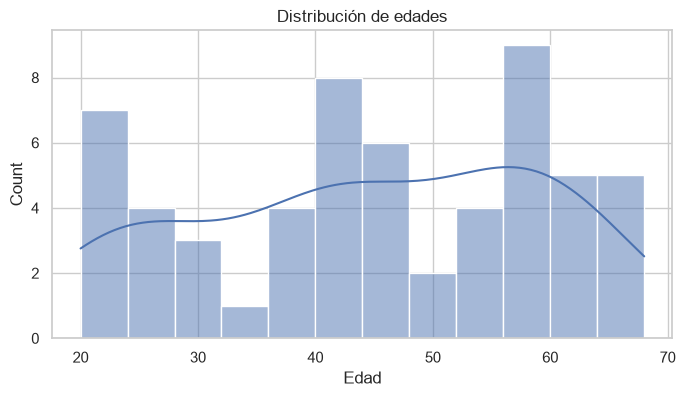

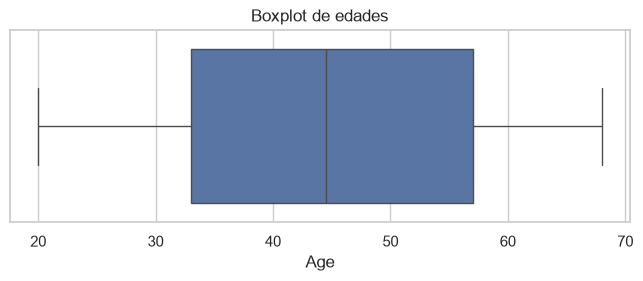

In [10]:
display(clientes_limpios["Age"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=clientes_limpios, x="Age", bins=12, kde=True)
plt.title("Distribución de edades")
plt.xlabel("Edad")
plt.show()

plt.figure(figsize=(8, 2.5))
sns.boxplot(data=clientes_limpios, x="Age")
plt.title("Boxplot de edades")
plt.show()

**Interpretación:**
- El histograma permite observar la forma de la distribución y dónde se concentran los valores.
- El boxplot resume mediana, cuartiles y posibles valores atípicos.
- Los puntos fuera de los bigotes son candidatos a revisión, no errores automáticamente.

### 5.2 Variables categóricas: género, ciudad y suscripción


Frecuencias de Gender


Gender
Masculino    30
Femenino     29
NaN           1
Name: count, dtype: int64

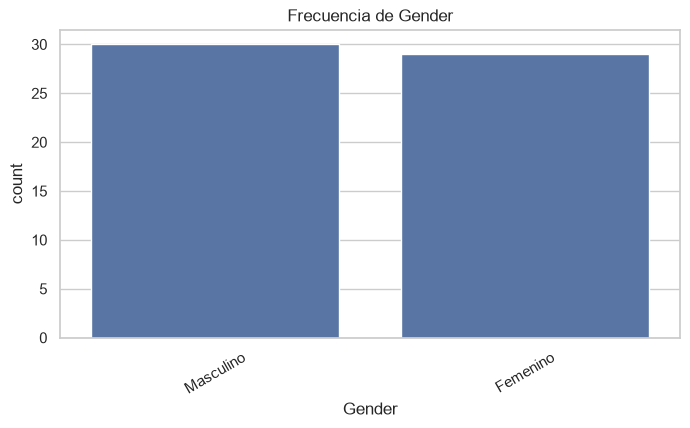

Frecuencias de City


City
Bogota      17
Medellin    16
Pereira     14
Cali        13
Name: count, dtype: Int64

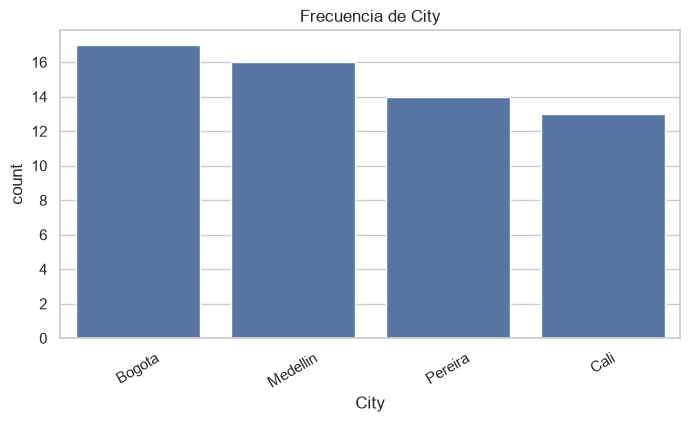

Frecuencias de Subscription


Subscription
Premium     22
Standard    20
Basic       18
Name: count, dtype: int64

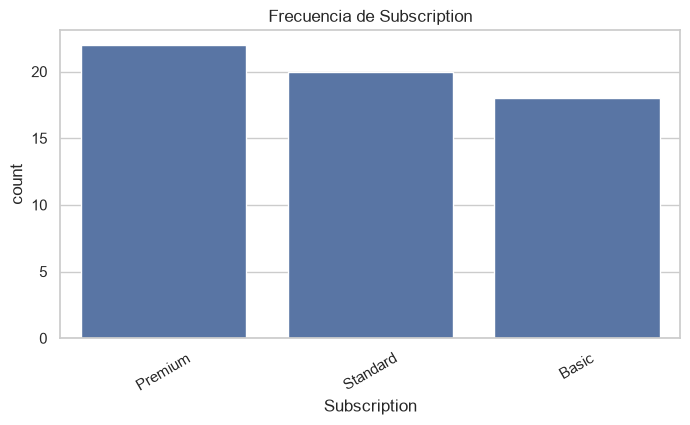

In [11]:
for columna in ["Gender", "City", "Subscription"]:
    print(f"Frecuencias de {columna}")
    display(clientes_limpios[columna].value_counts(dropna=False))

    plt.figure(figsize=(8, 4))
    orden = clientes_limpios[columna].value_counts().index
    sns.countplot(data=clientes_limpios, x=columna, order=orden)
    plt.title(f"Frecuencia de {columna}")
    plt.xticks(rotation=30)
    plt.show()

## 6. Análisis bivariado y multivariado

### 6.1 Preparar una tabla analítica

Para analizar compras según edad, ciudad o suscripción, necesitamos relacionar la tabla de transacciones con la de clientes.


In [12]:
datos = transacciones_limpias.merge(
    clientes_limpios,
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

display(datos.head())
print("Dimensiones de la tabla integrada:", datos.shape)

,Transaction_ID,Customer_ID,Date,Amount,Payment_Method,Age,Gender,City,Subscription
0,50001,1009,2025-01-01,108485.0,Transferencia,28.0,Femenino,Medellin,Basic
1,50002,1036,NaT,156888.0,Tarjeta,21.0,Femenino,Medellin,Basic
2,50003,1006,2025-03-01,355397.0,Efectivo,62.0,Femenino,Medellin,Premium
3,50004,1039,NaT,438026.0,Efectivo,32.0,Masculino,Medellin,Premium
4,50005,1038,2025-05-01,237815.0,Efectivo,61.0,Masculino,Medellin,Basic


Dimensiones de la tabla integrada: (155, 9)


### 6.2 Numérica + numérica: edad y monto de compra

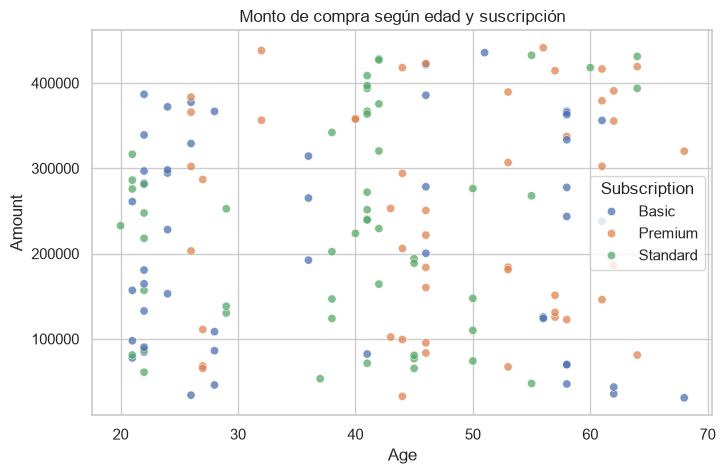

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=datos,
    x="Age",
    y="Amount",
    hue="Subscription",
    alpha=0.75
)
plt.title("Monto de compra según edad y suscripción")
plt.show()

### 6.3 Categórica + numérica: monto por suscripción

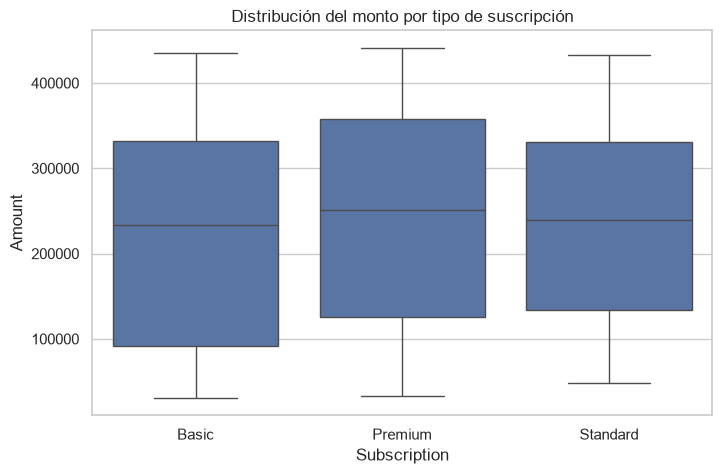

,count,mean,median,std
Subscription,,,,
Basic,50,218199.72,232956.5,125721.71
Premium,53,243263.72,250577.0,126529.71
Standard,51,235484.25,239424.0,121393.99


In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=datos, x="Subscription", y="Amount")
plt.title("Distribución del monto por tipo de suscripción")
plt.show()

display(
    datos.groupby("Subscription")["Amount"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

### 6.4 Varias variables: mapa de calor de correlaciones

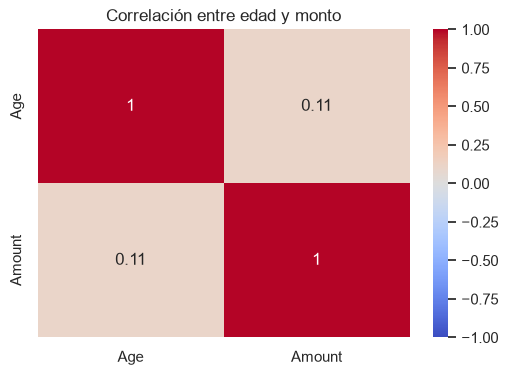

In [15]:
# Excluimos identificadores porque no representan magnitudes.
numericas = datos[["Age", "Amount"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(numericas, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre edad y monto")
plt.show()

**Interpretación:** la correlación describe la dirección e intensidad de una relación lineal. No demuestra causalidad. Además, no todas las columnas numéricas deben incluirse: los identificadores no representan magnitudes.

### 6.5 Fecha + numérica: compras por mes


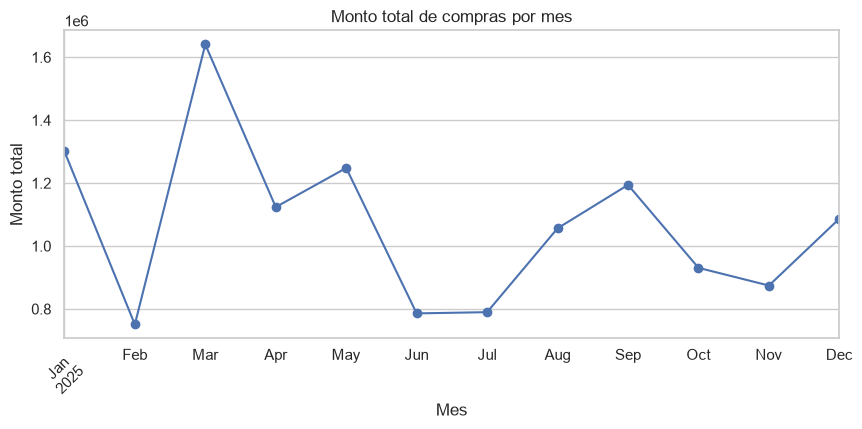

,total_compras
Month,
2025-01,1300997.0
2025-02,750611.0
2025-03,1640475.0
2025-04,1123675.0
2025-05,1247913.0
2025-06,785794.0
2025-07,789695.0
2025-08,1056198.0
2025-09,1194159.0


In [16]:
datos["Month"] = datos["Date"].dt.to_period("M")

compras_mes = (
    datos.dropna(subset=["Date"])
    .groupby("Month")["Amount"]
    .sum()
)

plt.figure(figsize=(10, 4))
compras_mes.plot(marker="o")
plt.title("Monto total de compras por mes")
plt.xlabel("Mes")
plt.ylabel("Monto total")
plt.xticks(rotation=45)
plt.show()

display(compras_mes.to_frame("total_compras"))

## 7. Cómo unir tablas en Python

En proyectos reales la información suele estar distribuida en varias tablas. Por ejemplo:
- `transacciones`: contiene las compras.
- `clientes`: contiene los datos de las personas.

La columna `Customer_ID` permite relacionarlas.

### 7.1 `merge()`: unir mediante una columna clave


In [17]:
ventas_clientes = pd.merge(
    transacciones_limpias,
    clientes_limpios,
    on="Customer_ID",
    how="left"
)

display(ventas_clientes.head())
print("Filas de transacciones:", len(transacciones_limpias))
print("Filas después del merge:", len(ventas_clientes))

,Transaction_ID,Customer_ID,Date,Amount,Payment_Method,Age,Gender,City,Subscription
0,50001,1009,2025-01-01,108485.0,Transferencia,28.0,Femenino,Medellin,Basic
1,50002,1036,NaT,156888.0,Tarjeta,21.0,Femenino,Medellin,Basic
2,50003,1006,2025-03-01,355397.0,Efectivo,62.0,Femenino,Medellin,Premium
3,50004,1039,NaT,438026.0,Efectivo,32.0,Masculino,Medellin,Premium
4,50005,1038,2025-05-01,237815.0,Efectivo,61.0,Masculino,Medellin,Basic


Filas de transacciones: 155
Filas después del merge: 155


**Tipos de unión (`how`):**

| Tipo | ¿Qué conserva? |
|---|---|
| `inner` | Solo las llaves que coinciden en ambas tablas. |
| `left` | Todas las filas de la tabla izquierda y coincidencias de la derecha. |
| `right` | Todas las filas de la tabla derecha y coincidencias de la izquierda. |
| `outer` | Todas las llaves de ambas tablas. |

Si queremos conservar todas las transacciones aunque falte información del cliente, usamos `how="left"` porque transacciones está a la izquierda.


### 7.2 Cuando las columnas llave tienen nombres diferentes

Utilizamos `left_on` y `right_on`.


In [18]:
clientes_aux = clientes_limpios.rename(
    columns={"Customer_ID": "ID_Cliente"}
)

ejemplo_merge = transacciones_limpias.merge(
    clientes_aux,
    left_on="Customer_ID",
    right_on="ID_Cliente",
    how="left"
)

display(ejemplo_merge.head())

,Transaction_ID,Customer_ID,Date,Amount,Payment_Method,ID_Cliente,Age,Gender,City,Subscription
0,50001,1009,2025-01-01,108485.0,Transferencia,1009,28.0,Femenino,Medellin,Basic
1,50002,1036,NaT,156888.0,Tarjeta,1036,21.0,Femenino,Medellin,Basic
2,50003,1006,2025-03-01,355397.0,Efectivo,1006,62.0,Femenino,Medellin,Premium
3,50004,1039,NaT,438026.0,Efectivo,1039,32.0,Masculino,Medellin,Premium
4,50005,1038,2025-05-01,237815.0,Efectivo,1038,61.0,Masculino,Medellin,Basic


### 7.4 `join()`: unir mediante índices

`join()` resulta práctico cuando la llave está en el índice de una o ambas tablas.


In [19]:
transacciones_indexadas = transacciones_limpias.set_index("Customer_ID")
clientes_indexados = clientes_limpios.set_index("Customer_ID")

resultado_join = transacciones_indexadas.join(
    clientes_indexados,
    how="left",
    rsuffix="_cliente"
)

display(resultado_join.head())

,Transaction_ID,Date,Amount,Payment_Method,Age,Gender,City,Subscription
Customer_ID,,,,,,,,
1009,50001,2025-01-01,108485.0,Transferencia,28.0,Femenino,Medellin,Basic
1036,50002,NaT,156888.0,Tarjeta,21.0,Femenino,Medellin,Basic
1006,50003,2025-03-01,355397.0,Efectivo,62.0,Femenino,Medellin,Premium
1039,50004,NaT,438026.0,Efectivo,32.0,Masculino,Medellin,Premium
1038,50005,2025-05-01,237815.0,Efectivo,61.0,Masculino,Medellin,Basic


### 7.5 ¿Cuál método elegir?

| Método | Uso principal |
|---|---|
| `merge()` | Relacionar tablas mediante una o varias columnas clave. |
| `join()` | Relacionar tablas utilizando sus índices. |

**Precaución:** después de unir, revisa el número de filas, la unicidad de las llaves y los registros sin correspondencia. Una unión puede multiplicar filas si la llave no es única en una de las tablas.


In [20]:
print(
    "Customer_ID único en clientes:",
    clientes_limpios["Customer_ID"].is_unique
)
print(
    "Customer_ID único en transacciones:",
    transacciones_limpias["Customer_ID"].is_unique
)

verificacion = transacciones_limpias.merge(
    clientes_limpios,
    on="Customer_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

display(verificacion["_merge"].value_counts())

Customer_ID único en clientes: True
Customer_ID único en transacciones: False


_merge
both          155
left_only       0
right_only      0
Name: count, dtype: int64